# Threshold between equal and unequal subunit pairs

Minimal re-run of notebook 32 (no R cells). Must sit in the same folder as notebook 32, because `WORK_DIR = 'ccprofiler_files'` is relative.

## 0. Setup

In [1]:
from pathlib import Path
import re

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from pyteomics import mass, parser
from scipy.stats import spearmanr
from procompa import get_project_root
import matplotlib.cm as cm
import matplotlib.colors as mcolors



PRJ_ROOT = get_project_root()
data_dir = PRJ_ROOT / "data"
cofrac_data_dir =  data_dir / "cofrac"
portal_dir = data_dir/ "Complex_Portal"
sequence_data_dir = data_dir / 'iPTM_and_pLDDT'


%config InlineBackend.figure_format = "retina"
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 9})
pl.Config.set_tbl_rows(12)
BLUE, ORANGE, GREY = '#2a78d6', '#eb6834', '#888780'


CF_FILES = {'highglu': 'highglu.tsv', 'nacl': 'nacl.tsv', 'ypd': 'ypd.tsv'}
COMPLEX_FILE = 'Saccharomyces_cerevisiae_ComplexTab.tsv'
SEQUENCE_FILE = 'all_CF_YM_yeast_proteins_uniprot_mapped_sequences.csv'

WORK_DIR = 'ccprofiler_files'                      # tables exchanged between Python and R
Path(WORK_DIR).mkdir(exist_ok=True)

N_FRACTIONS = 60
Q_CUTOFF = 0.05
N_CORES = 1                                        # CCprofiler cores; raise this only on a compute node

for file_name in [*CF_FILES.values(), COMPLEX_FILE]:
    assert (cofrac_data_dir / file_name).exists(), f'missing input file: {cofrac_data_dir / file_name}'
assert (sequence_data_dir / SEQUENCE_FILE).exists(), f'missing input file: {sequence_data_dir / SEQUENCE_FILE}'


## 1. Elution profiles

In [2]:
FRACTION_COLUMNS = [str(i) for i in range(1, N_FRACTIONS + 1)]

def read_profiles(path):
    wide = (pl.read_csv(path, separator='\t', infer_schema_length=0)        # read as text: some columns are empty
              .with_columns(pl.col(FRACTION_COLUMNS).cast(pl.Float64).fill_null(0)))
    assert wide.columns == ['ID', *FRACTION_COLUMNS], f'{path}: expected ID + fractions 1..{N_FRACTIONS}'
    assert wide['ID'].is_unique().all(), f'{path}: duplicated IDs'
    return wide

profiles_wide = {condition: read_profiles(cofrac_data_dir / file_name) for condition, file_name in CF_FILES.items()}
profiles_wide['highglu'].head()

ID,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""P0C5R9""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,22097.844,16380.963,29986.148,31155.9,19424.547,14636.092,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""P03875""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,35184.9,95155.46,228527.22,663732.06,568166.56,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""P00410""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,4778.473,34428.086,22215.281,42210.91,46920.9,32430.82,30135.215,35351.61,11644.201,8468.228,9983.028,7965.838,6973.484,12418.893,7540.567,7035.867,5221.679,5473.873,4831.0146,3174.3264,4629.427,4496.3345,2917.5918,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""P39714""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2727.935,5756.823,11278.288,26878.35,52431.52,64903.684,227087.16,385942.84,710290.56,468790.16,364865.8,202893.75,127663.37,102478.484,80755.836,85972.14,72677.37
"""P39726""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3981.1946,14156.326,9510.102,18156.055,38399.387,32859.535,79139.94,195643.97,500502.88,715126.1,508061.0,262811.22,127700.77,74796.14,43423.805


In [3]:
protein_groups = pl.concat([wide.filter(pl.col('ID').str.contains(';')).select(pl.lit(condition).alias('condition'), 'ID')
                            for condition, wide in profiles_wide.items()])
profiles_wide = {condition: wide.filter(~pl.col('ID').str.contains(';')) for condition, wide in profiles_wide.items()}
protein_groups.group_by('ID').agg(pl.col('condition')).sort('ID')

ID,condition
str,list[str]
"""[P02407;P14127]""","[""highglu"", ""nacl"", ""ypd""]"
"""[P04911;P04912]""","[""highglu"", ""nacl"", ""ypd""]"
"""[P07280;P07281]""","[""highglu"", ""nacl"", ""ypd""]"
"""[P0C0T4;Q3E792]""","[""highglu"", ""nacl"", ""ypd""]"
"""[P0C0W1;Q3E7Y3]""","[""highglu"", ""nacl"", ""ypd""]"
"""[P0C0W9;Q3E757]""","[""highglu"", ""nacl"", ""ypd""]"
"""[P0C0X0;Q3E7X9]""","[""highglu"", ""nacl"", ""ypd""]"
"""[P0C2J4;Q12392]""","[""highglu"", ""nacl""]"
"""[P0CX14;P53819]""","[""highglu"", ""nacl""]"


## 2. Complexes from Complex Portal

In [4]:
PARTICIPANT = re.compile(r'(\[[^\]]+\]|[^|()]+)\((\d+)\)')
UNIPROT = re.compile(r'^[OPQ][0-9][A-Z0-9]{3}[0-9]|^[A-NR-Z][0-9]')

portal = pl.read_csv(portal_dir / COMPLEX_FILE, separator='\t', quote_char=None, infer_schema_length=0)

member_rows, complex_rows = [], []
for complex_id, complex_name, identifiers, expanded in portal.select(
        '#Complex ac', 'Recommended name', 'Identifiers (and stoichiometry) of molecules in complex',
        'Expanded participant list').iter_rows():
    identifiers, expanded = identifiers or '', expanded or '-'
    participants = PARTICIPANT.findall(expanded if expanded != '-' else identifiers)
    proteins = {acc.split('-')[0]: int(copies) for acc, copies in participants if UNIPROT.match(acc)}
    has_paralogue_set = '[' in identifiers or '[' in expanded
    complex_rows.append(dict(complex_id=complex_id, complex_name=complex_name, n_proteins=len(proteins),
                             has_paralogue_set=has_paralogue_set, has_non_protein=len(proteins) < len(participants),
                             copies_known=bool(proteins) and all(c > 0 for c in proteins.values())))
    if not has_paralogue_set:
        member_rows += [dict(complex_id=complex_id, complex_name=complex_name, protein_id=acc, copies=copies)
                        for acc, copies in proteins.items()]

complex_overview = pl.DataFrame(complex_rows)
complex_members = (pl.DataFrame(member_rows)
                     .join(complex_overview.select('complex_id', 'n_proteins', 'has_non_protein', 'copies_known'), on='complex_id')
                     .filter(pl.col('n_proteins') >= 2))
complex_overview.select(
    complexes=pl.len(), with_paralogue_set=pl.col('has_paralogue_set').sum(),
    usable=(~pl.col('has_paralogue_set') & (pl.col('n_proteins') >= 2)).sum(),
    usable_with_known_copies=(~pl.col('has_paralogue_set') & (pl.col('n_proteins') >= 2) & pl.col('copies_known')).sum())

complexes,with_paralogue_set,usable,usable_with_known_copies
u32,u32,u32,u32
634,2,614,283


## 3. Protein masses and tryptic peptides

In [5]:
VALID_RESIDUES = set('ACDEFGHIKLMNPQRSTVWY') | {'U'}

sequences = (pl.read_csv(sequence_data_dir / SEQUENCE_FILE)
               .select('uniprot_id', 'sequence')
               .drop_nulls('sequence')
               .with_columns(pl.col('sequence').str.replace_all('*', '', literal=True).str.strip_chars()))
print(f'{sequences.height} rows, {sequences["uniprot_id"].n_unique()} accessions; '
      f'{sequences.filter(pl.col("uniprot_id").is_duplicated())["uniprot_id"].n_unique()} accessions appear more than once (first kept)')
sequences = sequences.unique('uniprot_id', keep='first', maintain_order=True)
unexpected = {aa for seq in sequences['sequence'] for aa in seq} - VALID_RESIDUES
assert not unexpected, f'unexpected residue letters: {unexpected}'

def n_tryptic_peptides(sequence):
    return len(parser.cleave(sequence, parser.expasy_rules['trypsin'], min_length=6, max_length=30))

protein_info = sequences.select(
    protein_id=pl.col('uniprot_id'),
    mass_kda=pl.col('sequence').map_elements(lambda s: mass.calculate_mass(sequence=s, average=True) / 1000, return_dtype=pl.Float64),
    n_tryptic_peptides=pl.col('sequence').map_elements(n_tryptic_peptides, return_dtype=pl.Int64))
proteins_without_peptides = (protein_info.filter(pl.col('n_tryptic_peptides') == 0)
                               .join(sequences.select(protein_id='uniprot_id', sequence='sequence'), on='protein_id')
                               .with_columns(length=pl.col('sequence').str.len_chars()))
proteins_without_peptides

2954 rows, 2954 accessions; 0 accessions appear more than once (first kept)


protein_id,mass_kda,n_tryptic_peptides,sequence,length
str,f64,i64,str,u32
"""P0CX86""",3.337115,0,"""MRAKWRKKRTRRLKRKRRKVRARSK""",25
"""P00856""",5.822201,0,"""MPQLVPFYFMNQLTYGFLLMITLLILFSQF…",48
"""Q99380""",3.984685,0,"""MISDEQLNSLAITFGIVMMTLIVIYHAVDS…",36


In [18]:
print(f'{proteins_without_peptides.height} proteins without a 6-30 aa tryptic peptide; their per-peptide intensity stays empty')
protein_info = protein_info.with_columns(
    n_tryptic_peptides=pl.when(pl.col('n_tryptic_peptides') > 0).then(pl.col('n_tryptic_peptides'))) 

3 proteins without a 6-30 aa tryptic peptide; their per-peptide intensity stays empty


## 4. CCprofiler output (read from files)

`CONDITIONS` is normally defined in the cell that writes the CCprofiler input files, which is skipped here.

In [7]:
CONDITIONS = list(CF_FILES)

In [8]:
best_features = pl.concat([pl.read_csv(f'{WORK_DIR}/complex_features_best_{condition}.tsv', separator='\t')
                             .select(pl.lit(condition).alias('condition'), 'complex_id', 'complex_name', 'n_subunits_annotated',
                                     'n_subunits_detected', 'subunits_detected', 'left_pp', 'apex', 'right_pp',
                                     'peak_corr', 'coelution_score', 'qvalue')
                           for condition in CONDITIONS])
best_features.group_by('condition').agg(
    complexes_with_q_below_cutoff=pl.len(),
    of_which_anchors=pl.col('complex_id').str.starts_with('ANCHOR').sum()).sort('condition')

condition,complexes_with_q_below_cutoff,of_which_anchors
str,u32,u32
"""highglu""",228,6
"""nacl""",273,6
"""ypd""",146,4


## 5. Detected subunits

In [9]:
feature_subunits = (best_features
                      .filter(~pl.col('complex_id').str.starts_with('ANCHOR'))
                      .with_columns(protein_id=pl.col('subunits_detected').str.split(';'))
                      .explode('protein_id')
                      .join(complex_members.select('complex_id', 'protein_id', 'copies', 'copies_known', 'has_non_protein'),
                            on=['complex_id', 'protein_id'], how='left')
                      .join(protein_info, on='protein_id', how='left'))
assert feature_subunits['copies'].null_count() == 0, 'a detected subunit is not a member of its complex'
feature_subunits.select('condition', 'complex_id', 'complex_name', 'protein_id', 'copies', 'copies_known', 'mass_kda', 'apex').head()

condition,complex_id,complex_name,protein_id,copies,copies_known,mass_kda,apex
str,str,str,str,i64,bool,f64,i64
"""highglu""","""CPX-1021""","""DNF1-LEM3 P4-ATPase complex""","""P32660""",0,false,177.796331,12
"""highglu""","""CPX-1021""","""DNF1-LEM3 P4-ATPase complex""","""P42838""",0,false,47.437099,12
"""highglu""","""CPX-1039""","""COMPASS complex""","""P36104""",1,true,37.12171,15
"""highglu""","""CPX-1039""","""COMPASS complex""","""P38123""",1,true,34.753404,15
"""highglu""","""CPX-1039""","""COMPASS complex""","""P39706""",1,true,48.654312,15


## 6. Stoichiometry from intensities

In [10]:
#For each subunit, sums the raw intensities from the input table over fractions left_pp to right_pp
intensity_rows = []
for row in feature_subunits.filter('copies_known', pl.col('mass_kda').is_not_null()).iter_rows(named=True):
    wide = profiles_wide[row['condition']]
    peak_columns = [str(f) for f in range(row['left_pp'], row['right_pp'] + 1)]
    intensity = wide.filter(pl.col('ID') == row['protein_id']).select(peak_columns).to_numpy().sum()
    intensity_rows.append(dict(condition=row['condition'], complex_id=row['complex_id'], complex_name=row['complex_name'],
                               protein_id=row['protein_id'], copies=row['copies'], left_pp=row['left_pp'], right_pp=row['right_pp'],
                               raw=intensity, per_mass=intensity / row['mass_kda'], per_peptide=intensity / row['n_tryptic_peptides'] if row['n_tryptic_peptides'] is not None else None))
subunit_intensities = pl.DataFrame(intensity_rows, infer_schema_length=None).filter(pl.col('raw') > 0)
subunit_intensities.head()

condition,complex_id,complex_name,protein_id,copies,left_pp,right_pp,raw,per_mass,per_peptide
str,str,str,str,i64,i64,i64,f64,f64,f64
"""highglu""","""CPX-1039""","""COMPASS complex""","""P36104""",1,10,20,57072.9301,1537.45422,3357.231182
"""highglu""","""CPX-1039""","""COMPASS complex""","""P38123""",1,10,20,30902.4253,889.191333,2809.311391
"""highglu""","""CPX-1039""","""COMPASS complex""","""P39706""",1,10,20,57438.684,1180.546632,2871.9342
"""highglu""","""CPX-1039""","""COMPASS complex""","""P43132""",2,10,20,144843.882,2482.462816,4138.396629
"""highglu""","""CPX-1039""","""COMPASS complex""","""Q03012""",2,10,20,68692.6124,1656.52558,3271.076781


In [11]:
pair_rows = []
for (condition, complex_id), group in subunit_intensities.group_by('condition', 'complex_id'):
    records = group.to_dicts()
    for i in range(len(records)):
        for j in range(i + 1, len(records)):
            first, second = sorted([records[i], records[j]], key=lambda r: -r['copies'])     # higher copy number first
            pair = dict(condition=condition, complex_id=complex_id, complex_name=first['complex_name'],
                        protein_high_copies=first['protein_id'], protein_low_copies=second['protein_id'],
                        copies=f"{first['copies']}:{second['copies']}", expected_log2=np.log2(first['copies'] / second['copies']))
            for quantity in ['raw', 'per_mass', 'per_peptide']:
                both_known = first[quantity] is not None and second[quantity] is not None
                pair[f'observed_log2_{quantity}'] = np.log2(first[quantity] / second[quantity]) if both_known else None
            pair_rows.append(pair)
all_subunit_pairs = pl.DataFrame(pair_rows, infer_schema_length=None).sort('condition', 'complex_id')

# the same protein pair can occur in several complexes within a condition (e.g. V-ATPase CPX-1192 / CPX-1193):
# keep it once, from the complex whose feature is most significant (lowest q; ties -> highest co-elution score, then complex_id)
complex_significance = best_features.select('condition', 'complex_id', 'qvalue', 'coelution_score')
assert not complex_significance.select('condition', 'complex_id').is_duplicated().any(), 'more than one best feature per complex and condition'

first_protein, second_protein = pl.col('protein_high_copies'), pl.col('protein_low_copies')
pairs_with_significance = (all_subunit_pairs
    .join(complex_significance, on=['condition', 'complex_id'], how='left')
    .with_columns(pair_key_a=pl.when(first_protein < second_protein).then(first_protein).otherwise(second_protein),   # orientation-free key:
                  pair_key_b=pl.when(first_protein < second_protein).then(second_protein).otherwise(first_protein)))  # copies can differ per complex
assert pairs_with_significance['qvalue'].null_count() == 0, 'a pair has no q-value from best_features'
assert pairs_with_significance['coelution_score'].null_count() == 0, 'a pair has no co-elution score from best_features'

duplicated_pair_groups = (pairs_with_significance
    .group_by('condition', 'pair_key_a', 'pair_key_b')
    .agg(n_complexes=pl.len(), copy_ratios=pl.col('copies').unique(), orientations=pl.col('protein_high_copies').n_unique())
    .filter(pl.col('n_complexes') > 1))
print(f'{duplicated_pair_groups.height} protein pairs occur in more than one complex within a condition; '
      f'{duplicated_pair_groups.filter(pl.col("copy_ratios").list.len() > 1).height} of them with different copy ratios, '
      f'{duplicated_pair_groups.filter(pl.col("orientations") > 1).height} with the higher-copy protein swapped')

subunit_pairs = (pairs_with_significance
    .sort(['qvalue', 'coelution_score', 'complex_id'], descending=[False, True, False])
    .unique(['condition', 'pair_key_a', 'pair_key_b'], keep='first', maintain_order=True)
    .drop('pair_key_a', 'pair_key_b')
    .sort('condition', 'complex_id'))
assert subunit_pairs.height == all_subunit_pairs.height - (duplicated_pair_groups['n_complexes'] - 1).sum()
print(f'{all_subunit_pairs.height - subunit_pairs.height} duplicate pairs removed; {subunit_pairs.height} pairs left '
      f'({(subunit_pairs["expected_log2"] > 0).sum()} unequal, {(subunit_pairs["expected_log2"] == 0).sum()} equal)')
subunit_pairs.head()

510 protein pairs occur in more than one complex within a condition; 41 of them with different copy ratios, 8 with the higher-copy protein swapped
615 duplicate pairs removed; 6008 pairs left (386 unequal, 5622 equal)


condition,complex_id,complex_name,protein_high_copies,protein_low_copies,copies,expected_log2,observed_log2_raw,observed_log2_per_mass,observed_log2_per_peptide,qvalue,coelution_score
str,str,str,str,str,str,f64,f64,f64,f64,f64,f64
"""highglu""","""CPX-1039""","""COMPASS complex""","""P43132""","""Q03323""","""2:1""",1.0,1.59316,0.007984,-0.536123,0.015116,0.999991
"""highglu""","""CPX-1039""","""COMPASS complex""","""P43132""","""Q03012""","""2:2""",0.0,1.076272,0.583612,0.339306,0.015116,0.999991
"""highglu""","""CPX-1039""","""COMPASS complex""","""P36104""","""P39706""","""1:1""",0.0,-0.009216,0.381088,0.225249,0.015116,0.999991
"""highglu""","""CPX-1039""","""COMPASS complex""","""P43132""","""P36104""","""2:1""",1.0,1.34362,0.691229,0.3018,0.015116,0.999991
"""highglu""","""CPX-1039""","""COMPASS complex""","""Q03012""","""P36104""","""2:1""",1.0,0.267348,0.107617,-0.037506,0.015116,0.999991


In [12]:
stoichiometry_rows = []
for quantity in ['raw', 'per_mass', 'per_peptide']:
    observed = f'observed_log2_{quantity}'
    unequal = subunit_pairs.filter(pl.col('expected_log2') > 0).drop_nulls(observed)
    equal = subunit_pairs.filter(pl.col('expected_log2') == 0).drop_nulls(observed)
    stoichiometry_rows.append(dict(
        quantity=quantity,
        unequal_pairs=unequal.height, unequal_complexes=unequal['complex_id'].n_unique(),
        share_higher_copy_more_signal=round(float((unequal[observed] > 0).mean()), 2),
        median_observed_minus_expected_log2=round(float((unequal[observed] - unequal['expected_log2']).median()), 2),
        equal_pairs=equal.height,
        equal_pairs_median_fold=round(float(2 ** equal[observed].abs().median()), 2)))
stoichiometry_summary = pl.DataFrame(stoichiometry_rows)

print(stoichiometry_summary)

# --- cap: every protein in at most MAX_UNEQUAL_PAIRS_PER_PROTEIN unequal pairs, over all complexes and conditions, both sides of a pair ---
# --- cap: every protein in at most MAX_STOICHIOMETRY_PAIRS_PER_PROTEIN equal pairs AND at most that many unequal pairs
#     (two separate counters), over all complexes and conditions, both sides of a pair ---
MAX_STOICHIOMETRY_PAIRS_PER_PROTEIN = 10
N_CAP_DRAWS = 100                     # which pairs a protein keeps is random; repeat and report the spread
STOICHIOMETRY_QUANTITIES = ['raw', 'per_mass', 'per_peptide']

pairs_with_all_quantities = subunit_pairs.drop_nulls([f'observed_log2_{quantity}' for quantity in STOICHIOMETRY_QUANTITIES])
equal_pairs_all_quantities = pairs_with_all_quantities.filter(pl.col('expected_log2') == 0)
unequal_pairs_all_quantities = pairs_with_all_quantities.filter(pl.col('expected_log2') > 0)
print(f'{equal_pairs_all_quantities.height} equal and {unequal_pairs_all_quantities.height} unequal pairs '
      f'with all three quantities go into the cap')

def cap_stoichiometry_pairs_per_protein(pairs, max_pairs_per_protein, seed):
    '''Go through the pairs in random order; keep a pair only if neither of its proteins has reached the cap.'''
    shuffled_pairs = pairs.sample(fraction=1.0, shuffle=True, seed=seed)
    kept_pairs_per_protein, keep_pair = {}, []
    for protein_high, protein_low in shuffled_pairs.select('protein_high_copies', 'protein_low_copies').iter_rows():
        keep = (kept_pairs_per_protein.get(protein_high, 0) < max_pairs_per_protein
                and kept_pairs_per_protein.get(protein_low, 0) < max_pairs_per_protein)
        if keep:
            kept_pairs_per_protein[protein_high] = kept_pairs_per_protein.get(protein_high, 0) + 1
            kept_pairs_per_protein[protein_low] = kept_pairs_per_protein.get(protein_low, 0) + 1
        keep_pair.append(keep)
    capped_pairs = shuffled_pairs.filter(pl.Series(keep_pair))
    assert capped_pairs.height > 0, 'cap removed every pair'
    assert max(kept_pairs_per_protein.values()) <= max_pairs_per_protein
    return capped_pairs

def stoichiometry_pair_metrics(equal_pair_set, unequal_pair_set):
    unequal_pair_proteins = pl.concat([unequal_pair_set['protein_high_copies'], unequal_pair_set['protein_low_copies']])
    equal_pair_proteins = pl.concat([equal_pair_set['protein_high_copies'], equal_pair_set['protein_low_copies']])
    metrics = dict(n_unequal_pairs=unequal_pair_set.height, n_unequal_complexes=unequal_pair_set['complex_id'].n_unique(),
                   n_unequal_proteins=unequal_pair_proteins.n_unique(),
                   n_equal_pairs=equal_pair_set.height, n_equal_proteins=equal_pair_proteins.n_unique())
    for quantity in STOICHIOMETRY_QUANTITIES:
        unequal_observed_log2 = unequal_pair_set[f'observed_log2_{quantity}']
        equal_observed_log2 = equal_pair_set[f'observed_log2_{quantity}']
        metrics[f'{quantity}_share_higher_copy_more_signal'] = float((unequal_observed_log2 > 0).mean())
        metrics[f'{quantity}_median_observed_minus_expected_log2'] = float((unequal_observed_log2 - unequal_pair_set['expected_log2']).median())
        metrics[f'{quantity}_equal_pairs_median_fold'] = float(2 ** equal_observed_log2.abs().median())
    return metrics

capped_pair_metrics = pl.DataFrame([
    stoichiometry_pair_metrics(
        cap_stoichiometry_pairs_per_protein(equal_pairs_all_quantities, MAX_STOICHIOMETRY_PAIRS_PER_PROTEIN, seed),
        cap_stoichiometry_pairs_per_protein(unequal_pairs_all_quantities, MAX_STOICHIOMETRY_PAIRS_PER_PROTEIN, seed))
    for seed in range(N_CAP_DRAWS)])
uncapped_pair_metrics = stoichiometry_pair_metrics(equal_pairs_all_quantities, unequal_pairs_all_quantities)

capped_pair_summary = (capped_pair_metrics.select(pl.all().cast(pl.Float64))
    .unpivot(variable_name='metric')
    .group_by('metric', maintain_order=True)
    .agg(capped_median=pl.col('value').median(),
         capped_low=pl.col('value').quantile(0.025), capped_high=pl.col('value').quantile(0.975))
    .with_columns(uncapped=pl.col('metric').replace_strict({name: float(value) for name, value in uncapped_pair_metrics.items()},
                                                           return_dtype=pl.Float64))
    .with_columns(pl.col(pl.Float64).round(2)))
with pl.Config(tbl_rows=-1):
    print(capped_pair_summary)

shape: (3, 7)
┌─────────────┬──────────────┬─────────────┬─────────────┬─────────────┬─────────────┬─────────────┐
│ quantity    ┆ unequal_pair ┆ unequal_com ┆ share_highe ┆ median_obse ┆ equal_pairs ┆ equal_pairs │
│ ---         ┆ s            ┆ plexes      ┆ r_copy_more ┆ rved_minus_ ┆ ---         ┆ _median_fol │
│ str         ┆ ---          ┆ ---         ┆ _signal     ┆ expected…   ┆ i64         ┆ d           │
│             ┆ i64          ┆ i64         ┆ ---         ┆ ---         ┆             ┆ ---         │
│             ┆              ┆             ┆ f64         ┆ f64         ┆             ┆ f64         │
╞═════════════╪══════════════╪═════════════╪═════════════╪═════════════╪═════════════╪═════════════╡
│ raw         ┆ 386          ┆ 27          ┆ 0.78        ┆ 0.36        ┆ 5622        ┆ 2.28        │
│ per_mass    ┆ 386          ┆ 27          ┆ 0.93        ┆ 0.44        ┆ 5622        ┆ 1.85        │
│ per_peptide ┆ 386          ┆ 27          ┆ 0.92        ┆ 0.34        ┆ 5622

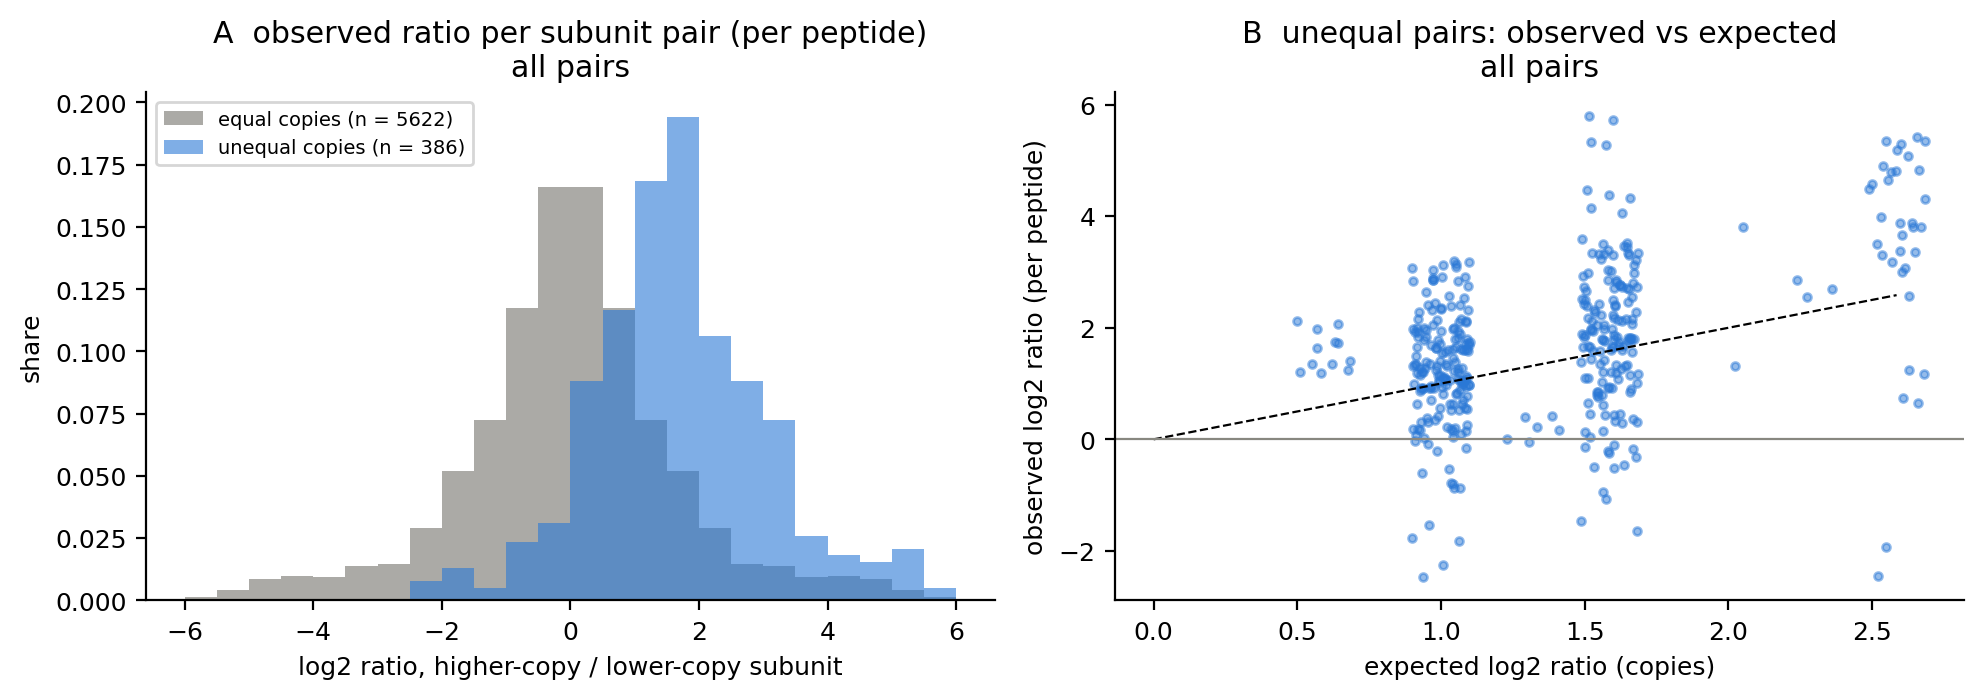

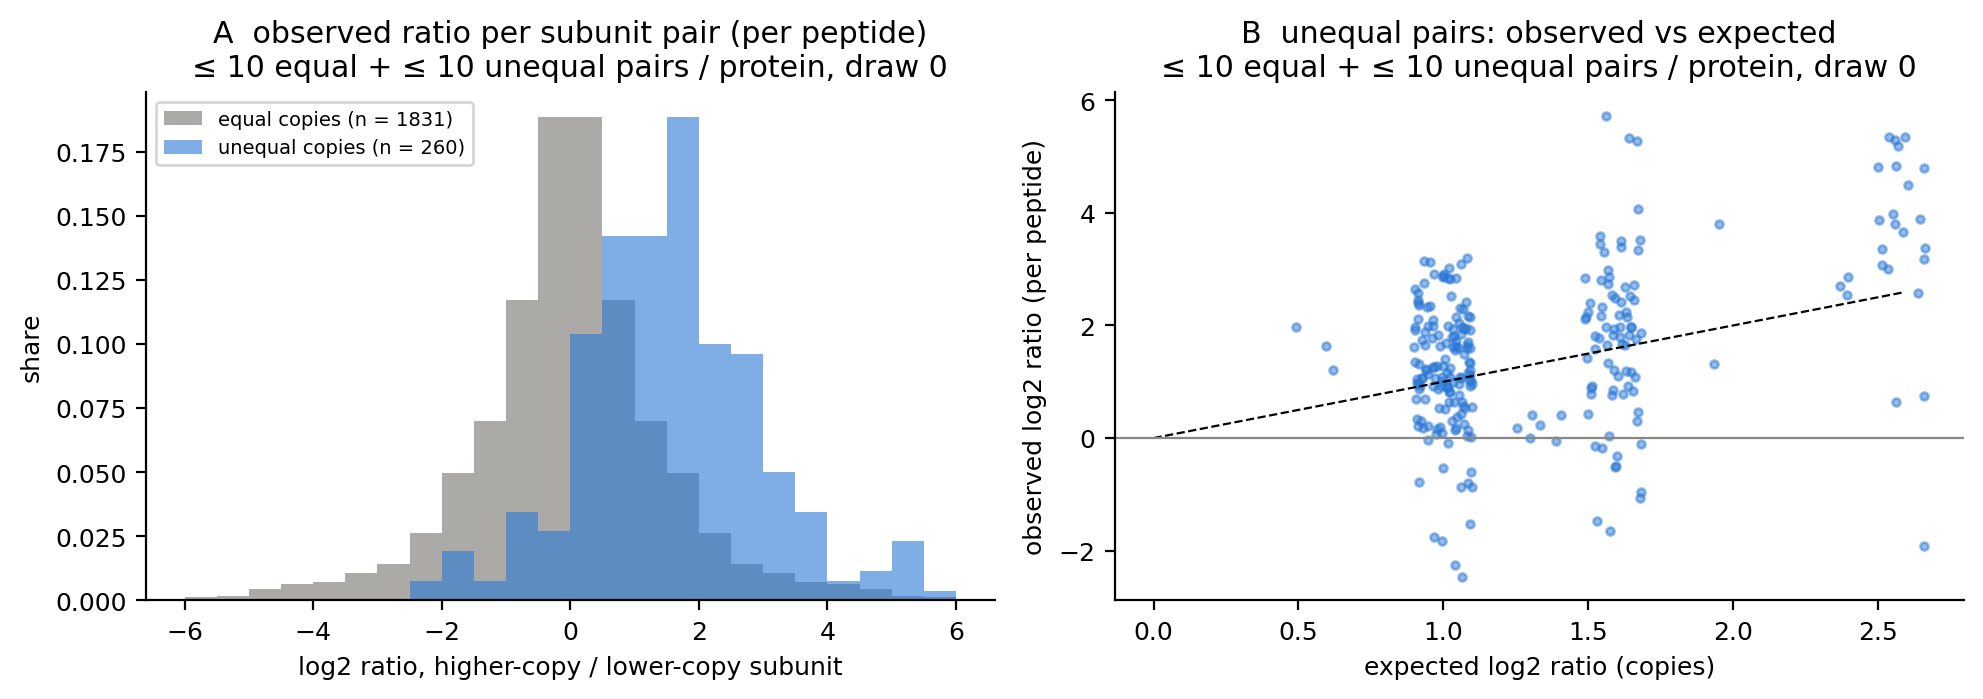

In [13]:
for variable_name in ['cap_stoichiometry_pairs_per_protein', 'equal_pairs_all_quantities', 'unequal_pairs_all_quantities',
                      'MAX_STOICHIOMETRY_PAIRS_PER_PROTEIN']:
    assert variable_name in globals(), f'run the stoichiometry summary / cap cell first ({variable_name} missing)'

OBSERVED_COLUMN = 'observed_log2_per_peptide'
PLOTTED_CAP_SEED = 0                # one draw is shown; the summary tables use the median over all draws

def plot_pair_ratios(equal_pair_set, unequal_pair_set, title_suffix):
    equal_ratios = equal_pair_set[OBSERVED_COLUMN].to_numpy()
    assert len(equal_ratios) > 0 and unequal_pair_set.height > 0, 'no equal or no unequal pairs to plot'
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
    bins = np.arange(-6, 6.1, 0.5)
    axes[0].hist(np.r_[equal_ratios, -equal_ratios], bins, weights=np.full(2 * len(equal_ratios), 1 / (2 * len(equal_ratios))),
                 color=GREY, alpha=0.7, label=f'equal copies (n = {len(equal_ratios)})')
    axes[0].hist(unequal_pair_set[OBSERVED_COLUMN], bins, weights=np.full(unequal_pair_set.height, 1 / unequal_pair_set.height),
                 color=BLUE, alpha=0.6, label=f'unequal copies (n = {unequal_pair_set.height})')
    axes[0].set(title=f'A  observed ratio per subunit pair (per peptide)\n{title_suffix}',
                xlabel='log2 ratio, higher-copy / lower-copy subunit', ylabel='share')
    axes[0].legend(fontsize=7)
    axes[1].scatter(unequal_pair_set['expected_log2'] + np.random.default_rng(0).uniform(-0.1, 0.1, unequal_pair_set.height),
                    unequal_pair_set[OBSERVED_COLUMN], s=8, alpha=0.5, c=BLUE)
    identity_line = np.array([0, unequal_pair_set['expected_log2'].max()])
    axes[1].plot(identity_line, identity_line, 'k--', lw=0.8)
    axes[1].axhline(0, color=GREY, lw=0.8)
    axes[1].set(title=f'B  unequal pairs: observed vs expected\n{title_suffix}',
                xlabel='expected log2 ratio (copies)', ylabel='observed log2 ratio (per peptide)')
    plt.tight_layout(); plt.show()

# uncapped: all pairs with a per-peptide value
uncapped_equal_pairs = subunit_pairs.filter(pl.col('expected_log2') == 0).drop_nulls(OBSERVED_COLUMN)
uncapped_unequal_pairs = subunit_pairs.filter(pl.col('expected_log2') > 0).drop_nulls(OBSERVED_COLUMN)
plot_pair_ratios(uncapped_equal_pairs, uncapped_unequal_pairs, 'all pairs')

# capped: one draw, same cap as the summary table
capped_equal_pairs = cap_stoichiometry_pairs_per_protein(equal_pairs_all_quantities, MAX_STOICHIOMETRY_PAIRS_PER_PROTEIN, PLOTTED_CAP_SEED)
capped_unequal_pairs = cap_stoichiometry_pairs_per_protein(unequal_pairs_all_quantities, MAX_STOICHIOMETRY_PAIRS_PER_PROTEIN, PLOTTED_CAP_SEED)
plot_pair_ratios(capped_equal_pairs, capped_unequal_pairs,
                 f'≤ {MAX_STOICHIOMETRY_PAIRS_PER_PROTEIN} equal + ≤ {MAX_STOICHIOMETRY_PAIRS_PER_PROTEIN} unequal pairs / protein, draw {PLOTTED_CAP_SEED}')

copy ratios in the capped pairs (draw 0):
shape: (8, 4)
┌────────────┬───────────────┬─────────┬─────────────┐
│ copy_ratio ┆ expected_log2 ┆ n_pairs ┆ n_complexes │
│ ---        ┆ ---           ┆ ---     ┆ ---         │
│ str        ┆ f64           ┆ u32     ┆ u32         │
╞════════════╪═══════════════╪═════════╪═════════════╡
│ 1:1        ┆ 0.0           ┆ 1831    ┆ 138         │
│ 3:2        ┆ 0.584963      ┆ 3       ┆ 1           │
│ 2:1        ┆ 1.0           ┆ 147     ┆ 18          │
│ 5:2        ┆ 1.321928      ┆ 6       ┆ 1           │
│ 3:1        ┆ 1.584963      ┆ 77      ┆ 7           │
│ 4:1        ┆ 2.0           ┆ 2       ┆ 2           │
│ 5:1        ┆ 2.321928      ┆ 3       ┆ 1           │
│ 6:1        ┆ 2.584963      ┆ 22      ┆ 2           │
└────────────┴───────────────┴─────────┴─────────────┘
compared (>= 10 pairs): ['1:1', '2:1', '3:1', '6:1']
AUC between copy ratios, median and 2.5–97.5% over 100 capped draws:
shape: (6, 8)
┌─────────────┬──────────────┬────────

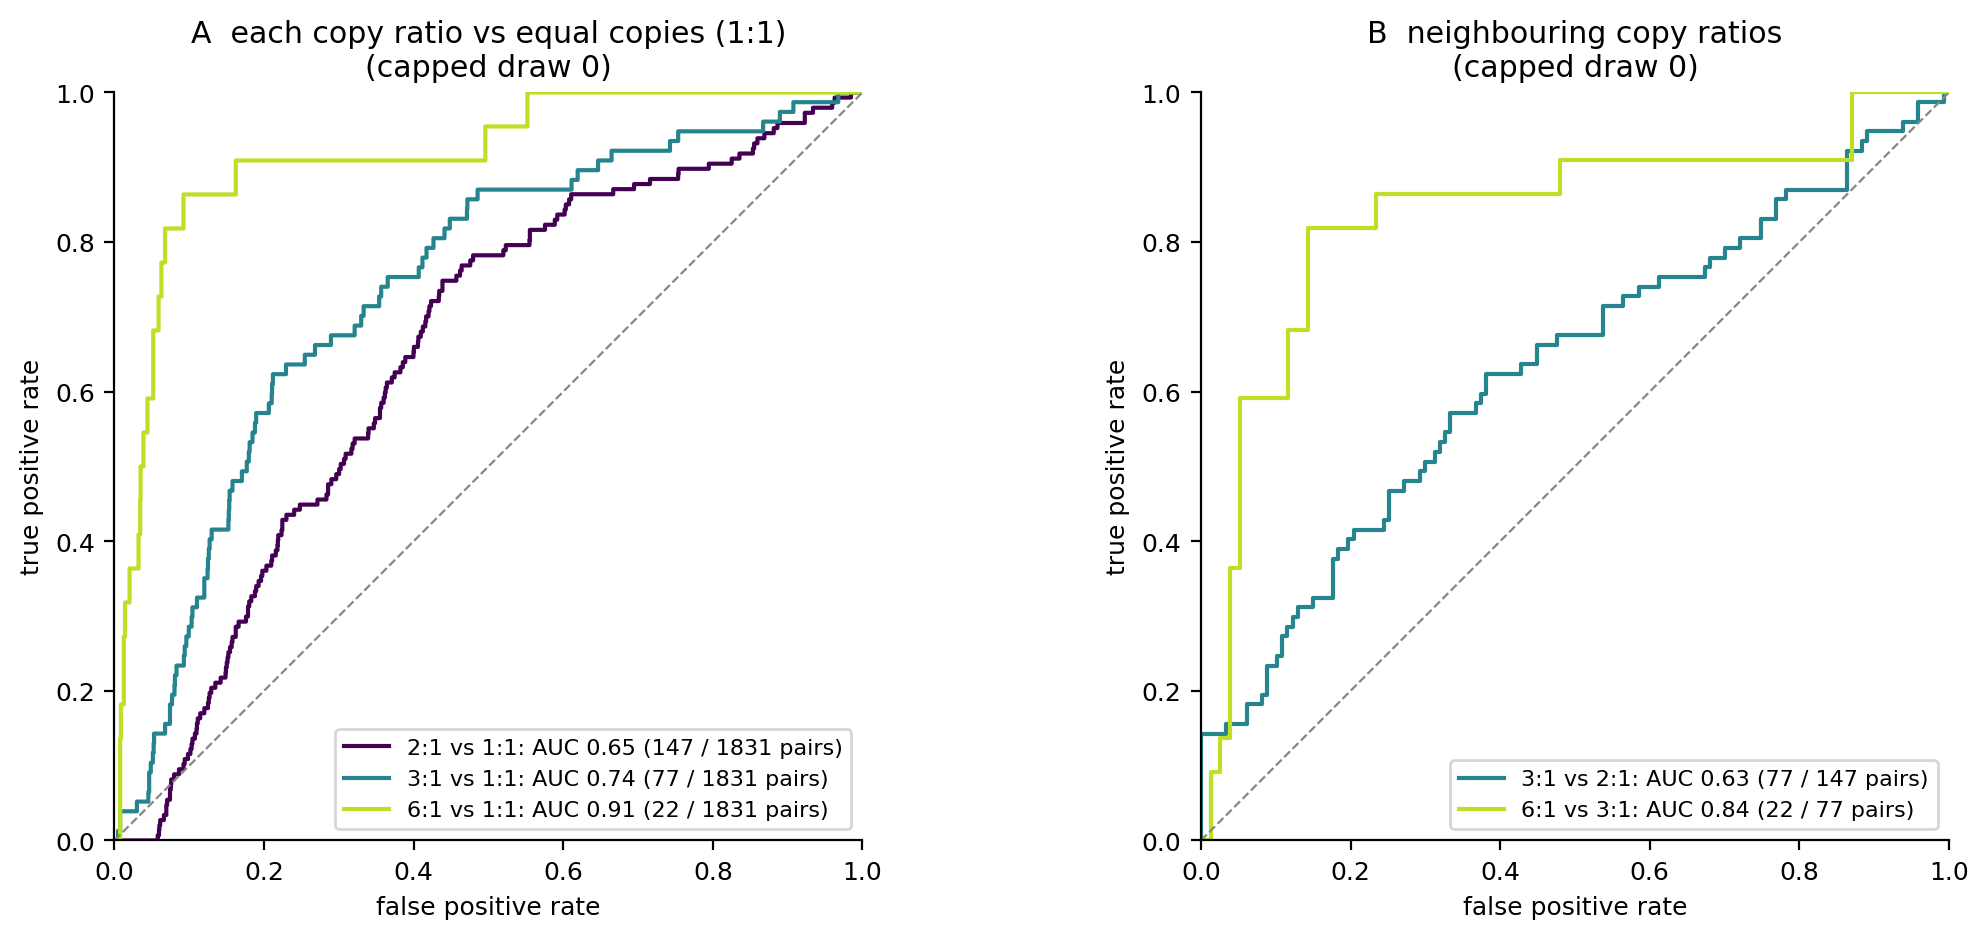

In [14]:
from scipy.stats import mannwhitneyu

for variable_name in ['capped_equal_pairs', 'capped_unequal_pairs', 'equal_pairs_all_quantities', 'unequal_pairs_all_quantities',
                      'cap_stoichiometry_pairs_per_protein', 'OBSERVED_COLUMN', 'MAX_STOICHIOMETRY_PAIRS_PER_PROTEIN',
                      'PLOTTED_CAP_SEED', 'N_CAP_DRAWS']:
    assert variable_name in globals(), f'run the stoichiometry summary / pair-ratio plot cells first ({variable_name} missing)'

MIN_PAIRS_PER_RATIO = 10               # copy ratios with fewer capped pairs (in the plotted draw) are left out

def with_copy_ratio(pair_set):
    '''Add the reduced copy ratio (4:2 -> 2:1, 2:2 -> 1:1) and the absolute observed log2 ratio.'''
    copies_high = pair_set['copies'].str.extract(r'^(\d+):\d+$', 1).cast(pl.Int64)
    copies_low = pair_set['copies'].str.extract(r'^\d+:(\d+)$', 1).cast(pl.Int64)
    assert copies_high.null_count() == 0 and copies_low.null_count() == 0, 'copies string not "int:int"'
    common_divisor = np.gcd(copies_high.to_numpy(), copies_low.to_numpy())
    reduced_ratio = [f'{high}:{low}' for high, low in zip(copies_high.to_numpy() // common_divisor, copies_low.to_numpy() // common_divisor)]
    return pair_set.with_columns(copy_ratio=pl.Series(reduced_ratio), absolute_log2_ratio=pl.col(OBSERVED_COLUMN).abs())

def capped_pairs_with_ratio(seed):
    return pl.concat([with_copy_ratio(cap_stoichiometry_pairs_per_protein(equal_pairs_all_quantities, MAX_STOICHIOMETRY_PAIRS_PER_PROTEIN, seed)),
                      with_copy_ratio(cap_stoichiometry_pairs_per_protein(unequal_pairs_all_quantities, MAX_STOICHIOMETRY_PAIRS_PER_PROTEIN, seed))])

def auc_higher_above_lower(lower_ratio_values, higher_ratio_values):
    '''Probability that a pair of the higher copy ratio has a larger |log2 ratio| than a pair of the lower one (ties count half).'''
    return (mannwhitneyu(higher_ratio_values, lower_ratio_values, alternative='greater').statistic
            / (len(higher_ratio_values) * len(lower_ratio_values)))

def roc_points(positive_values, negative_values):
    cut_offs = np.sort(np.unique(np.r_[positive_values, negative_values]))[::-1]
    true_positive_rate = np.r_[0, 1 - np.searchsorted(np.sort(positive_values), cut_offs, side='left') / len(positive_values)]
    false_positive_rate = np.r_[0, 1 - np.searchsorted(np.sort(negative_values), cut_offs, side='left') / len(negative_values)]
    return false_positive_rate, true_positive_rate

# --- copy-ratio classes in the plotted draw ---
plotted_draw_pairs = pl.concat([with_copy_ratio(capped_equal_pairs), with_copy_ratio(capped_unequal_pairs)])
assert plotted_draw_pairs.filter(pl.col('expected_log2') == 0)['copy_ratio'].eq('1:1').all(), 'an equal pair did not reduce to 1:1'
ratio_classes = (plotted_draw_pairs.group_by('copy_ratio')
                 .agg(expected_log2=pl.col('expected_log2').first(), n_pairs=pl.len(), n_complexes=pl.col('complex_id').n_unique())
                 .sort('expected_log2'))
print(f'copy ratios in the capped pairs (draw {PLOTTED_CAP_SEED}):')
print(ratio_classes)
compared_ratios = ratio_classes.filter(pl.col('n_pairs') >= MIN_PAIRS_PER_RATIO)['copy_ratio'].to_list()
assert len(compared_ratios) >= 2, f'fewer than two copy ratios with >= {MIN_PAIRS_PER_RATIO} pairs'
print(f'compared (>= {MIN_PAIRS_PER_RATIO} pairs): {compared_ratios}')

# --- AUC for every pair of copy ratios, over all capped draws ---
ratio_auc_rows = []
for seed in range(N_CAP_DRAWS):
    draw_pairs = capped_pairs_with_ratio(seed)
    values_by_ratio = {ratio: draw_pairs.filter(pl.col('copy_ratio') == ratio)['absolute_log2_ratio'].to_numpy() for ratio in compared_ratios}
    for lower_position, lower_ratio in enumerate(compared_ratios):
        for higher_ratio in compared_ratios[lower_position + 1:]:
            if len(values_by_ratio[lower_ratio]) == 0 or len(values_by_ratio[higher_ratio]) == 0:
                continue
            ratio_auc_rows.append(dict(seed=seed, lower_ratio=lower_ratio, higher_ratio=higher_ratio,
                                       n_lower=len(values_by_ratio[lower_ratio]), n_higher=len(values_by_ratio[higher_ratio]),
                                       auc=auc_higher_above_lower(values_by_ratio[lower_ratio], values_by_ratio[higher_ratio])))
ratio_auc_summary = (pl.DataFrame(ratio_auc_rows)
    .group_by('lower_ratio', 'higher_ratio', maintain_order=True)
    .agg(n_draws=pl.len(), median_n_lower=pl.col('n_lower').median(), median_n_higher=pl.col('n_higher').median(),
         auc_median=pl.col('auc').median(), auc_low=pl.col('auc').quantile(0.025), auc_high=pl.col('auc').quantile(0.975))
    .with_columns(pl.col('auc_median', 'auc_low', 'auc_high').round(2)))
with pl.Config(tbl_rows=-1, tbl_cols=-1, tbl_width_chars=200):
    print(f'AUC between copy ratios, median and 2.5–97.5% over {N_CAP_DRAWS} capped draws:')
    print(ratio_auc_summary)

# --- check the merging of copy ratios (e.g. 4:2 -> 2:1) ---
with pl.Config(tbl_rows=-1):
    print('original copies merged into a reduced ratio (plotted draw):')
    print(plotted_draw_pairs.filter(pl.col('copies') != pl.col('copy_ratio'))
          .group_by('copies', 'copy_ratio').agg(n_pairs=pl.len()).sort('copy_ratio', 'copies'))

# --- which comparisons: every unequal ratio vs equal (1:1), and neighbouring unequal ratios ---
assert compared_ratios[0] == '1:1', f'equal pairs (1:1) are not the lowest compared ratio: {compared_ratios}'
unequal_ratios = compared_ratios[1:]
assert len(unequal_ratios) >= 2, f'need at least two unequal copy ratios with >= {MIN_PAIRS_PER_RATIO} pairs: {unequal_ratios}'
comparisons_against_equal = [('1:1', unequal_ratio) for unequal_ratio in unequal_ratios]
neighbouring_comparisons = list(zip(unequal_ratios[:-1], unequal_ratios[1:]))

def auc_rows_for(comparisons):
    return pl.concat([ratio_auc_summary.filter((pl.col('lower_ratio') == lower_ratio) & (pl.col('higher_ratio') == higher_ratio))
                      for lower_ratio, higher_ratio in comparisons])

with pl.Config(tbl_rows=-1, tbl_cols=-1, tbl_width_chars=200):
    print(f'each unequal ratio vs equal (1:1), AUC median and 2.5–97.5% over {N_CAP_DRAWS} capped draws:')
    print(auc_rows_for(comparisons_against_equal))
    print(f'neighbouring unequal ratios, AUC median and 2.5–97.5% over {N_CAP_DRAWS} capped draws:')
    print(auc_rows_for(neighbouring_comparisons))

# --- figure: ROC curves from the plotted draw; one colour per unequal ratio (the higher ratio of each comparison) ---
ratio_colours = dict(zip(unequal_ratios, plt.get_cmap('viridis')(np.linspace(0, 0.9, len(unequal_ratios)))))

def plot_ratio_roc(ax, comparisons, x_label, title):
    for lower_ratio, higher_ratio in comparisons:
        lower_values = plotted_draw_pairs.filter(pl.col('copy_ratio') == lower_ratio)['absolute_log2_ratio'].to_numpy()
        higher_values = plotted_draw_pairs.filter(pl.col('copy_ratio') == higher_ratio)['absolute_log2_ratio'].to_numpy()
        assert len(lower_values) > 0 and len(higher_values) > 0, f'no pairs for {higher_ratio} vs {lower_ratio} in the plotted draw'
        false_positive_rate, true_positive_rate = roc_points(higher_values, lower_values)
        ax.plot(false_positive_rate, true_positive_rate, color=ratio_colours[higher_ratio], lw=1.5,
                label=f'{higher_ratio} vs {lower_ratio}: AUC {auc_higher_above_lower(lower_values, higher_values):.2f} '
                      f'({len(higher_values)} / {len(lower_values)} pairs)')
    ax.plot([0, 1], [0, 1], color=GREY, ls='--', lw=0.8)
    ax.set(xlim=(0, 1), ylim=(0, 1), aspect='equal', xlabel=x_label,
           ylabel='true positive rate', title=title)
    ax.legend(fontsize=8, loc='lower right')

fig, (ax_against_equal, ax_neighbours) = plt.subplots(1, 2, figsize=(11, 4.8))
plot_ratio_roc(ax_against_equal, comparisons_against_equal, 'false positive rate',
               f'A  each copy ratio vs equal copies (1:1)\n(capped draw {PLOTTED_CAP_SEED})')
plot_ratio_roc(ax_neighbours, neighbouring_comparisons, 'false positive rate',
               f'B  neighbouring copy ratios\n(capped draw {PLOTTED_CAP_SEED})')
plt.tight_layout(); plt.show()

## 7. Cutoff on |log2 intensity ratio| between equal and unequal pairs

Youden cutoff (max TPR − FPR) and the lowest cutoff with FPR ≤ 10%, computed per capped draw; median and 5–95% range over draws.

In [15]:
for variable_name in ['capped_pairs_with_ratio', 'N_CAP_DRAWS']:
    assert variable_name in globals(), f'run the cells above first ({variable_name} missing)'

TARGET_FALSE_POSITIVE_RATE = 0.10

threshold_rows = []
for seed in range(N_CAP_DRAWS):
    draw_pairs = capped_pairs_with_ratio(seed)
    unequal_absolute_log2 = draw_pairs.filter(pl.col('expected_log2') > 0)['absolute_log2_ratio'].to_numpy()
    equal_absolute_log2 = draw_pairs.filter(pl.col('expected_log2') == 0)['absolute_log2_ratio'].to_numpy()
    assert len(unequal_absolute_log2) > 0 and len(equal_absolute_log2) > 0, f'draw {seed}: a pair group is empty'

    candidate_cutoffs = np.sort(np.unique(np.r_[unequal_absolute_log2, equal_absolute_log2]))
    true_positive_rates = np.array([(unequal_absolute_log2 >= cutoff).mean() for cutoff in candidate_cutoffs])
    false_positive_rates = np.array([(equal_absolute_log2 >= cutoff).mean() for cutoff in candidate_cutoffs])

    youden_index = int(np.argmax(true_positive_rates - false_positive_rates))
    fixed_fpr_candidates = np.flatnonzero(false_positive_rates <= TARGET_FALSE_POSITIVE_RATE)
    assert fixed_fpr_candidates.size > 0, f'draw {seed}: no cutoff reaches FPR <= {TARGET_FALSE_POSITIVE_RATE}'
    fixed_fpr_index = int(fixed_fpr_candidates[0])          # lowest cutoff that still keeps FPR at or below target

    threshold_rows.append(dict(
        seed=seed,
        youden_cutoff_log2=candidate_cutoffs[youden_index],
        youden_tpr=true_positive_rates[youden_index], youden_fpr=false_positive_rates[youden_index],
        fixed_fpr_cutoff_log2=candidate_cutoffs[fixed_fpr_index],
        fixed_fpr_tpr=true_positive_rates[fixed_fpr_index], fixed_fpr_fpr=false_positive_rates[fixed_fpr_index],
    ))

equal_unequal_thresholds = pl.DataFrame(threshold_rows)
threshold_metric_columns = [column for column in equal_unequal_thresholds.columns if column != 'seed']
threshold_summary = equal_unequal_thresholds.select(
    [pl.col(column).median().alias(f'{column}_median') for column in threshold_metric_columns]
    + [pl.col(column).quantile(0.05).alias(f'{column}_q05') for column in ['youden_cutoff_log2', 'fixed_fpr_cutoff_log2']]
    + [pl.col(column).quantile(0.95).alias(f'{column}_q95') for column in ['youden_cutoff_log2', 'fixed_fpr_cutoff_log2']]
).with_columns(youden_cutoff_fold=2 ** pl.col('youden_cutoff_log2_median'),
               fixed_fpr_cutoff_fold=2 ** pl.col('fixed_fpr_cutoff_log2_median'))

with pl.Config(tbl_rows=-1):
    print(threshold_summary.transpose(include_header=True, header_name='metric', column_names=['value']))


shape: (12, 2)
┌──────────────────────────────┬──────────┐
│ metric                       ┆ value    │
│ ---                          ┆ ---      │
│ str                          ┆ f64      │
╞══════════════════════════════╪══════════╡
│ youden_cutoff_log2_median    ┆ 0.864368 │
│ youden_tpr_median            ┆ 0.769231 │
│ youden_fpr_median            ┆ 0.43877  │
│ fixed_fpr_cutoff_log2_median ┆ 2.409219 │
│ fixed_fpr_tpr_median         ┆ 0.247104 │
│ fixed_fpr_fpr_median         ┆ 0.099726 │
│ youden_cutoff_log2_q05       ┆ 0.837277 │
│ fixed_fpr_cutoff_log2_q05    ┆ 2.341882 │
│ youden_cutoff_log2_q95       ┆ 1.059436 │
│ fixed_fpr_cutoff_log2_q95    ┆ 2.481493 │
│ youden_cutoff_fold           ┆ 1.820542 │
│ fixed_fpr_cutoff_fold        ┆ 5.311866 │
└──────────────────────────────┴──────────┘


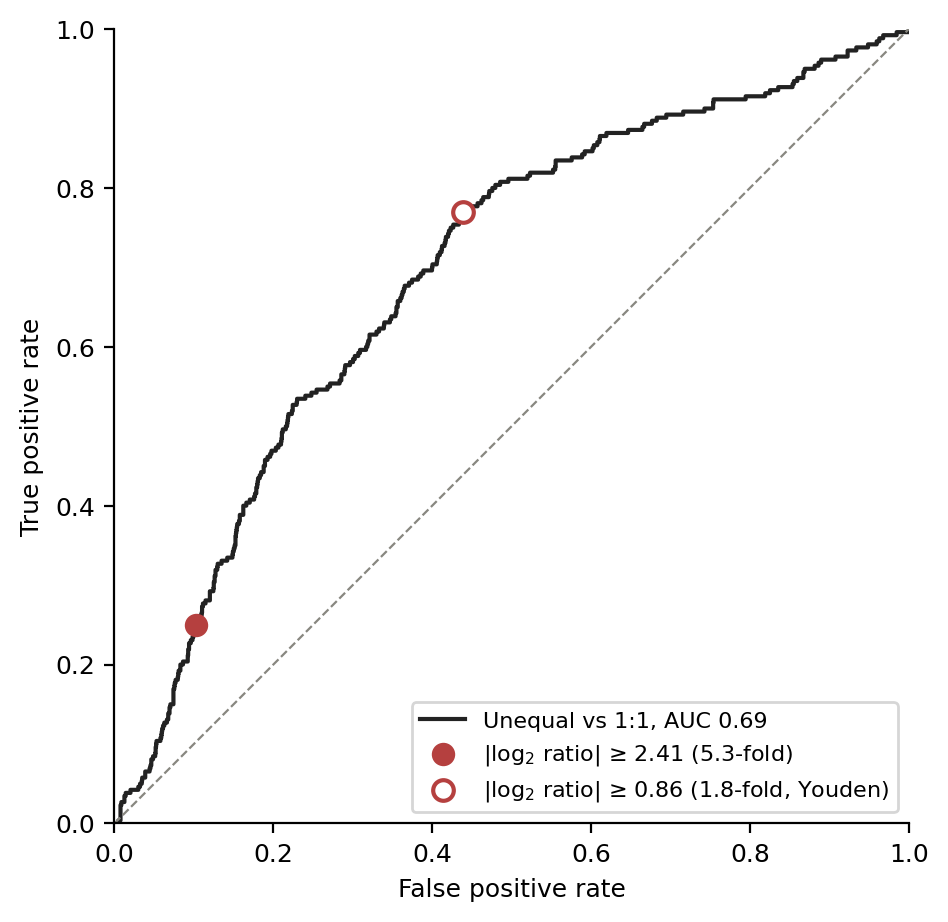

plotted draw 0: stringent cutoff at FPR 0.10, TPR 0.25; Youden at FPR 0.44, TPR 0.77


In [16]:
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

for variable_name in ['threshold_summary', 'capped_pairs_with_ratio', 'N_CAP_DRAWS']:
    assert variable_name in globals(), f'run the threshold cell first ({variable_name} missing)'

PLOTTED_CAP_SEED = 0
UNEQUAL_COLOUR, CUTOFF_COLOUR, DIAGONAL_COLOUR = '#222222', '#b5403f', '#888780'

stringent_cutoff_log2 = threshold_summary['fixed_fpr_cutoff_log2_median'][0]
youden_cutoff_log2 = threshold_summary['youden_cutoff_log2_median'][0]


def unequal_and_equal_absolute_log2(seed):
    draw_pairs = capped_pairs_with_ratio(seed)
    return (draw_pairs.filter(pl.col('expected_log2') > 0)['absolute_log2_ratio'].to_numpy(),
            draw_pairs.filter(pl.col('expected_log2') == 0)['absolute_log2_ratio'].to_numpy())


def auc_unequal_above_equal(unequal_values, equal_values):
    return mannwhitneyu(unequal_values, equal_values, alternative='greater').statistic / (len(unequal_values) * len(equal_values))


auc_per_draw = [auc_unequal_above_equal(*unequal_and_equal_absolute_log2(seed)) for seed in range(N_CAP_DRAWS)]
median_auc_unequal_vs_equal = float(np.median(auc_per_draw))

plotted_unequal_log2, plotted_equal_log2 = unequal_and_equal_absolute_log2(PLOTTED_CAP_SEED)
roc_cutoffs = np.sort(np.unique(np.r_[plotted_unequal_log2, plotted_equal_log2]))[::-1]
roc_true_positive_rate = np.r_[0, [(plotted_unequal_log2 >= cutoff).mean() for cutoff in roc_cutoffs]]
roc_false_positive_rate = np.r_[0, [(plotted_equal_log2 >= cutoff).mean() for cutoff in roc_cutoffs]]

# where the median cutoffs fall on the plotted draw's curve
stringent_point = ((plotted_equal_log2 >= stringent_cutoff_log2).mean(), (plotted_unequal_log2 >= stringent_cutoff_log2).mean())
youden_point = ((plotted_equal_log2 >= youden_cutoff_log2).mean(), (plotted_unequal_log2 >= youden_cutoff_log2).mean())

fig, ax = plt.subplots(figsize=(4.8, 4.8))
ax.plot(roc_false_positive_rate, roc_true_positive_rate, color=UNEQUAL_COLOUR, lw=1.5,
        label=f'Unequal vs 1:1, AUC {median_auc_unequal_vs_equal:.2f}')
ax.plot([0, 1], [0, 1], color=DIAGONAL_COLOUR, ls='--', lw=0.8)
ax.scatter(*stringent_point, s=55, color=CUTOFF_COLOUR, zorder=3,
           label=f'|log$_2$ ratio| ≥ {stringent_cutoff_log2:.2f} ({2 ** stringent_cutoff_log2:.1f}-fold)')
ax.scatter(*youden_point, s=55, facecolor='white', edgecolor=CUTOFF_COLOUR, lw=1.5, zorder=3,
           label=f'|log$_2$ ratio| ≥ {youden_cutoff_log2:.2f} ({2 ** youden_cutoff_log2:.1f}-fold, Youden)')
ax.set(xlim=(0, 1), ylim=(0, 1), aspect='equal', xlabel='False positive rate', ylabel='True positive rate')
ax.legend(fontsize=8, loc='lower right')
plt.tight_layout()
plt.show()

print(f'plotted draw {PLOTTED_CAP_SEED}: stringent cutoff at FPR {stringent_point[0]:.2f}, TPR {stringent_point[1]:.2f}; '
      f'Youden at FPR {youden_point[0]:.2f}, TPR {youden_point[1]:.2f}')

In [22]:
for variable_name in ['capped_pairs_with_ratio', 'N_CAP_DRAWS', 'threshold_summary']:
    assert variable_name in globals(), f'run the threshold cell first ({variable_name} missing)'

TESTED_CUTOFFS_FOLD = [1.25, 1.5, 2, 3, 4, 6, 8, 16]
tested_cutoffs = (
    [dict(cutoff_name=f'{fold}-fold', cutoff_log2=float(np.log2(fold))) for fold in TESTED_CUTOFFS_FOLD]
    + [dict(cutoff_name='Youden', cutoff_log2=threshold_summary['youden_cutoff_log2_median'][0]),
       dict(cutoff_name='FPR ≤ 10%', cutoff_log2=threshold_summary['fixed_fpr_cutoff_log2_median'][0])]
)

error_rate_rows = []
for seed in range(N_CAP_DRAWS):
    draw_pairs = capped_pairs_with_ratio(seed)
    unequal_absolute_log2 = draw_pairs.filter(pl.col('expected_log2') > 0)['absolute_log2_ratio'].to_numpy()
    equal_absolute_log2 = draw_pairs.filter(pl.col('expected_log2') == 0)['absolute_log2_ratio'].to_numpy()
    assert len(unequal_absolute_log2) > 0 and len(equal_absolute_log2) > 0, f'draw {seed}: a pair group is empty'
    for cutoff in tested_cutoffs:
        error_rate_rows.append(dict(
            seed=seed, **cutoff,
            false_positive_rate=float((equal_absolute_log2 >= cutoff['cutoff_log2']).mean()),    # equal pairs called unequal
            false_negative_rate=float((unequal_absolute_log2 < cutoff['cutoff_log2']).mean()),   # unequal pairs missed
        ))

error_rates_per_cutoff = (
    pl.DataFrame(error_rate_rows)
    .group_by('cutoff_name', 'cutoff_log2', maintain_order=True)
    .agg(fpr_median=pl.col('false_positive_rate').median(),
         fpr_q05=pl.col('false_positive_rate').quantile(0.05),
         fpr_q95=pl.col('false_positive_rate').quantile(0.95),
         fnr_median=pl.col('false_negative_rate').median(),
         fnr_q05=pl.col('false_negative_rate').quantile(0.05),
         fnr_q95=pl.col('false_negative_rate').quantile(0.95))
    .with_columns(cutoff_fold=2 ** pl.col('cutoff_log2'))
    .sort('cutoff_log2')
    .select('cutoff_name', 'cutoff_log2', 'cutoff_fold', 'fpr_median', 'fpr_q05', 'fpr_q95',
            'fnr_median', 'fnr_q05', 'fnr_q95')
    .with_columns(pl.exclude('cutoff_name').round(3))
)

with pl.Config(tbl_rows=-1, tbl_cols=-1, tbl_width_chars=200):
    print(error_rates_per_cutoff)

shape: (10, 9)
┌─────────────┬─────────────┬─────────────┬────────────┬─────────┬─────────┬────────────┬─────────┬─────────┐
│ cutoff_name ┆ cutoff_log2 ┆ cutoff_fold ┆ fpr_median ┆ fpr_q05 ┆ fpr_q95 ┆ fnr_median ┆ fnr_q05 ┆ fnr_q95 │
│ ---         ┆ ---         ┆ ---         ┆ ---        ┆ ---     ┆ ---     ┆ ---        ┆ ---     ┆ ---     │
│ str         ┆ f64         ┆ f64         ┆ f64        ┆ f64     ┆ f64     ┆ f64        ┆ f64     ┆ f64     │
╞═════════════╪═════════════╪═════════════╪════════════╪═════════╪═════════╪════════════╪═════════╪═════════╡
│ 1.25-fold   ┆ 0.322       ┆ 1.25        ┆ 0.746      ┆ 0.737   ┆ 0.755   ┆ 0.104      ┆ 0.093   ┆ 0.116   │
│ 1.5-fold    ┆ 0.585       ┆ 1.5         ┆ 0.586      ┆ 0.574   ┆ 0.597   ┆ 0.166      ┆ 0.152   ┆ 0.178   │
│ Youden      ┆ 0.864       ┆ 1.821       ┆ 0.442      ┆ 0.43    ┆ 0.452   ┆ 0.229      ┆ 0.212   ┆ 0.247   │
│ 2-fold      ┆ 1.0         ┆ 2.0         ┆ 0.387      ┆ 0.374   ┆ 0.397   ┆ 0.304      ┆ 0.285   ┆ 0.32 

/cluster/project/beltrao/kdammer/master_thesis/.venv/lib/python3.11/site-packages/matplotlib/scale.py:170: RuntimeWarning: divide by zero encountered in log2
  return self._forward(values)


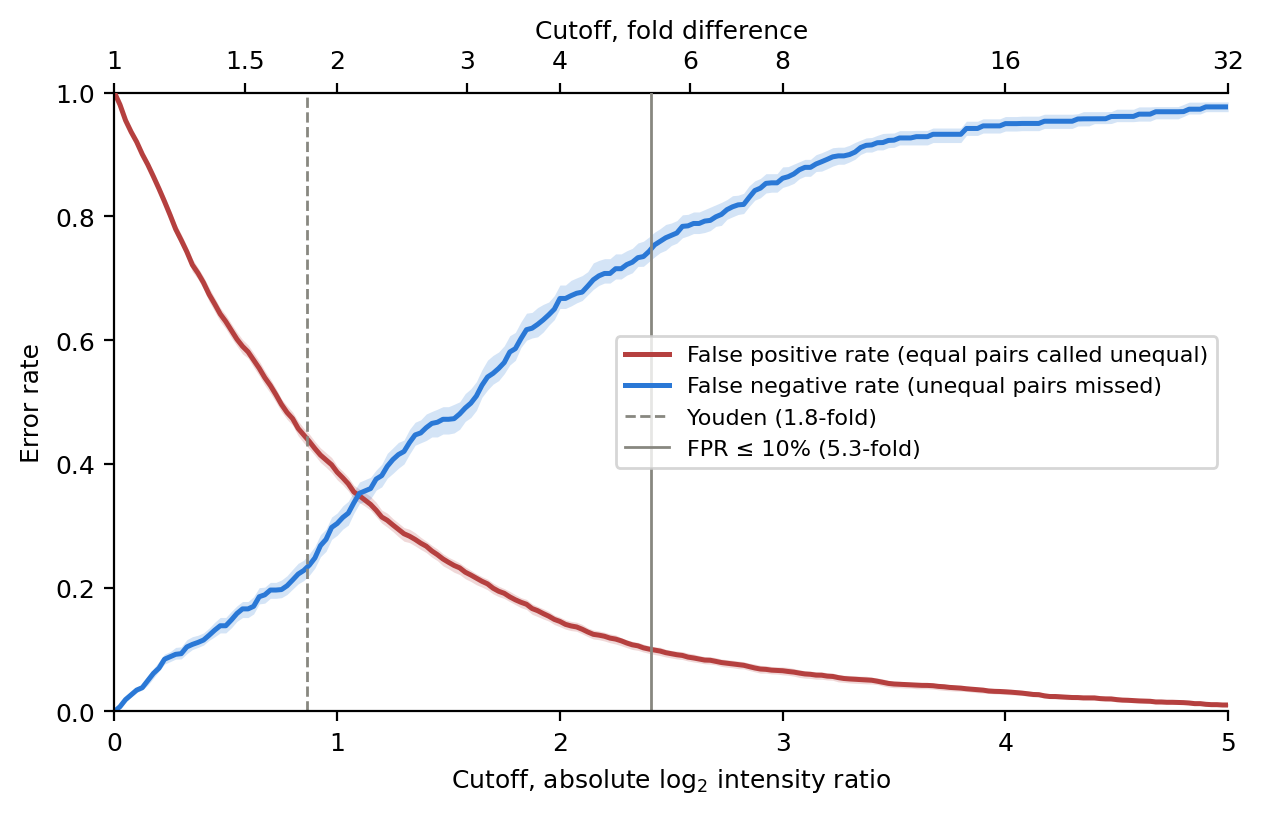

In [24]:
import matplotlib.pyplot as plt

for variable_name in ['capped_pairs_with_ratio', 'N_CAP_DRAWS', 'threshold_summary']:
    assert variable_name in globals(), f'run the threshold cell first ({variable_name} missing)'

CUTOFF_GRID_LOG2 = np.linspace(0, 5, 201)
FPR_COLOUR, FNR_COLOUR, CUTOFF_COLOUR = '#b5403f', '#2a78d6', '#888780'

stringent_cutoff_log2 = threshold_summary['fixed_fpr_cutoff_log2_median'][0]
youden_cutoff_log2 = threshold_summary['youden_cutoff_log2_median'][0]

fpr_per_draw, fnr_per_draw = [], []
for seed in range(N_CAP_DRAWS):
    draw_pairs = capped_pairs_with_ratio(seed)
    unequal_absolute_log2 = np.sort(draw_pairs.filter(pl.col('expected_log2') > 0)['absolute_log2_ratio'].to_numpy())
    equal_absolute_log2 = np.sort(draw_pairs.filter(pl.col('expected_log2') == 0)['absolute_log2_ratio'].to_numpy())
    assert len(unequal_absolute_log2) > 0 and len(equal_absolute_log2) > 0, f'draw {seed}: a pair group is empty'
    # equal pairs at or above the cutoff are false positives; unequal pairs below it are false negatives
    fpr_per_draw.append(1 - np.searchsorted(equal_absolute_log2, CUTOFF_GRID_LOG2, side='left') / len(equal_absolute_log2))
    fnr_per_draw.append(np.searchsorted(unequal_absolute_log2, CUTOFF_GRID_LOG2, side='left') / len(unequal_absolute_log2))
fpr_per_draw, fnr_per_draw = np.array(fpr_per_draw), np.array(fnr_per_draw)
assert fpr_per_draw.shape == fnr_per_draw.shape == (N_CAP_DRAWS, len(CUTOFF_GRID_LOG2))

fig, ax = plt.subplots(figsize=(6.4, 4.2))
for rates_per_draw, colour, label in [(fpr_per_draw, FPR_COLOUR, 'False positive rate (equal pairs called unequal)'),
                                      (fnr_per_draw, FNR_COLOUR, 'False negative rate (unequal pairs missed)')]:
    ax.fill_between(CUTOFF_GRID_LOG2, np.quantile(rates_per_draw, 0.05, axis=0), np.quantile(rates_per_draw, 0.95, axis=0),
                    color=colour, alpha=0.2, lw=0)
    ax.plot(CUTOFF_GRID_LOG2, np.median(rates_per_draw, axis=0), color=colour, lw=1.8, label=label)

ax.axvline(youden_cutoff_log2, color=CUTOFF_COLOUR, ls='--', lw=1,
           label=f'Youden ({2 ** youden_cutoff_log2:.1f}-fold)')
ax.axvline(stringent_cutoff_log2, color=CUTOFF_COLOUR, ls='-', lw=1,
           label=f'FPR ≤ 10% ({2 ** stringent_cutoff_log2:.1f}-fold)')
ax.set(xlim=(CUTOFF_GRID_LOG2[0], CUTOFF_GRID_LOG2[-1]), ylim=(0, 1),
       xlabel='Cutoff, absolute log$_2$ intensity ratio', ylabel='Error rate')

fold_axis = ax.secondary_xaxis('top', functions=(lambda log2_value: 2 ** log2_value, np.log2))
fold_axis.set_xticks([1, 1.5, 2, 3, 4, 6, 8, 16, 32])
fold_axis.set_xticklabels(['1', '1.5', '2', '3', '4', '6', '8', '16', '32'])
fold_axis.set_xlabel('Cutoff, fold difference')

ax.legend(fontsize=8, loc='center right')
plt.tight_layout()
plt.show()